In [5]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.
Path to dataset files: C:\Users\gkahl\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [6]:
import pandas as pd
import os
file_path = os.path.join(path, "amz_uk_price_prediction_dataset.csv")
df = pd.read_csv(file_path)

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [ ]:
crosstab_cat_bests = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
#pd.set_option('display.max_rows', None)
crosstab_cat_bests.sort_values(by=True, ascending=False)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


In [34]:
crosstab_cat_bests.sort_values(by=True, ascending=False)[:20]

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Tableware,0.975904,0.024096
Arts & Crafts,0.975914,0.024086
Baby,0.977342,0.022658


For the categories "grocery", "smart home security & lighting" and "health & personal care", the proportion of bestsellers exceeds 5%. 

In [ ]:
crosstab_cat_bests_abs = pd.crosstab(df["category"], df["isBestSeller"])
crosstab_cat_bests_abs

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


### Cramér’s V Interpretation Guide (Cohen's Conventions)

| Cramér’s V | Strength of Association   |
|------------|----------------------------|
| 0.00–0.10  | Negligible / Very Weak     |
| 0.10–0.20  | Weak                       |
| 0.20–0.30  | Moderate                   |
| 0.30–0.50  | Strong                     |
| > 0.50     | Very Strong                |


In [ ]:
from scipy.stats import chi2_contingency
crosstab_cat_bests_abs = pd.crosstab(df["category"], df["isBestSeller"])
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_cat_bests_abs) # _ means I don't want to store these values
print("Chi²-Test: p-value < 0.05 is: ",float(chi2_pvalue) < 0.05)
from scipy.stats.contingency import association
cramers_v = association(crosstab_cat_bests_abs, method='cramer')
if cramers_v > 0.5:
    result = "very strong"
elif cramers_v > 0.3:
    result = "strong"
elif cramers_v > 0.2:
    result = "moderate"
elif cramers_v > 0.1:
    result = "weak"
else:
    result = "negligible"
print("Cramer-Test: V=", cramers_v, "-> association is", result)

Chi²-Test: Test statistic < 0.05 is:  True
Cramer-Test: V= 0.1222829439760564 -> association is weak


Chi²-Test gives high p-value, Cramer's V gives only a weak association. 

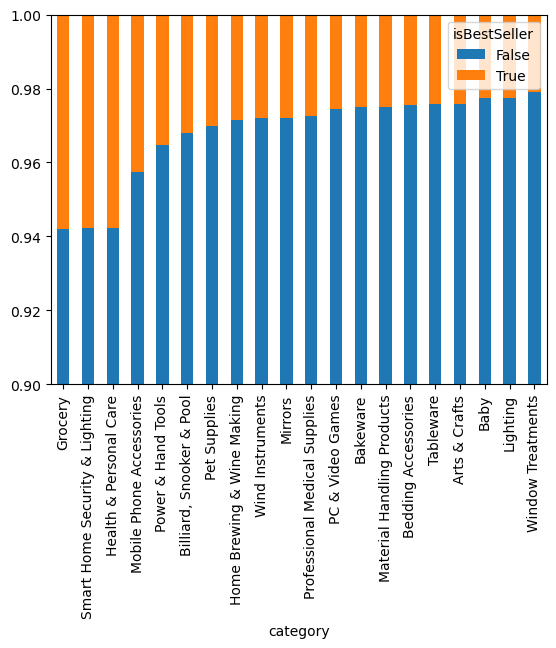

In [36]:
# stacked bar chart
import matplotlib.pyplot as plt
crosstab_cat_bests.sort_values(by=True, ascending=False)[:20].plot(kind='bar', stacked=True)
plt.ylim(0.9, 1)  # Zoom auf Bereich 0.9 bis 1
plt.show()

Comment: The stacked bar charts gives a good insight if you zoom in on the y axis, sort by highest relative frequency and look at the best 20 items. 


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [22]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [23]:
data_series = df["price"]  # look at price column
outliers = outlier_slayer(data_series)
df_outliers_removed = df[~df["price"].isin(outliers)]
df_outliers_removed.shape

(2115963, 9)

In [ ]:
top_categories = df_outliers_removed["category"].value_counts(ascending=False)[:4]
df_filtered = df_outliers_removed[df_outliers_removed["category"].isin(top_categories.index)]

C:\Users\gkahl\AppData\Local\Temp\ipykernel_14596\2998567693.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_filtered, x="category", y="price", order=top_categories.index, palette="coolwarm")


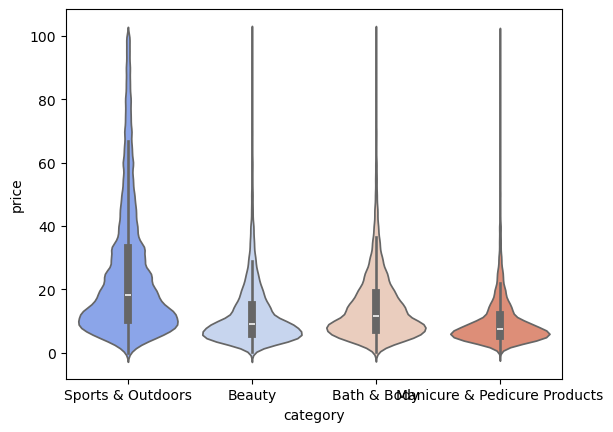

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.violinplot(data=df_filtered, x="category", y="price", order=top_categories.index, palette="coolwarm")
plt.show()

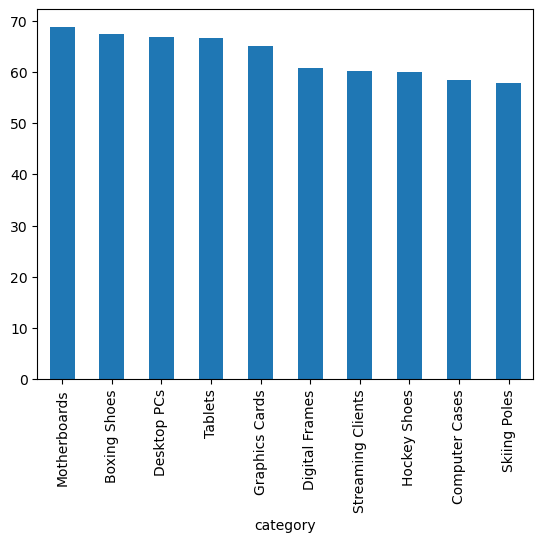

In [ ]:
avg_price = (
    df_outliers_removed
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
avg_price.plot(kind='bar')
plt.show()

In [ ]:
avg_price_total = (
    df_outliers_removed
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)
avg_price_total.idxmax
# Motherboards are commanding the highest prices.

<bound method Series.idxmax of category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64>

C:\Users\gkahl\AppData\Local\Temp\ipykernel_14596\3874410580.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered_boxplot, x="category", y="stars", palette="coolwarm", legend=True)


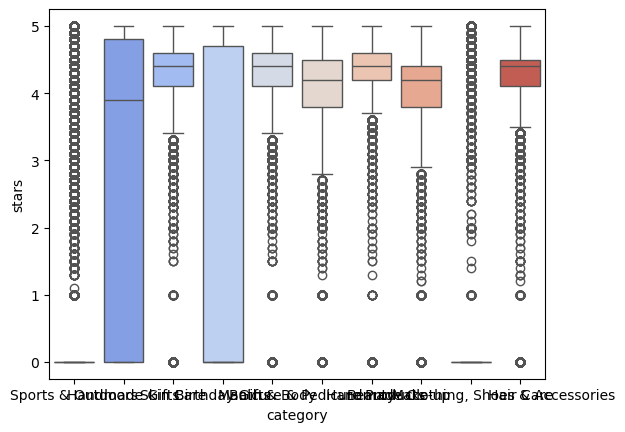

In [33]:
top_10categories = df_outliers_removed["category"].value_counts(ascending=False)[:10]
df_filtered_boxplot = df_outliers_removed[df_outliers_removed["category"].isin(top_10categories.index)]

sns.boxplot(data=df_filtered_boxplot, x="category", y="stars", palette="coolwarm", legend=True)
plt.show()

In [ ]:
ratings = (
    df_outliers_removed
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)
ratings
# Computer Memory tends to get the highest median ratings.

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [38]:
df_filtered[["price","stars"]].corr()
# The correlation coefficient is very low with 0.057, so there does not appear to be a linear association.

,price,stars
price,1.000000,0.057451
stars,0.057451,1.000000


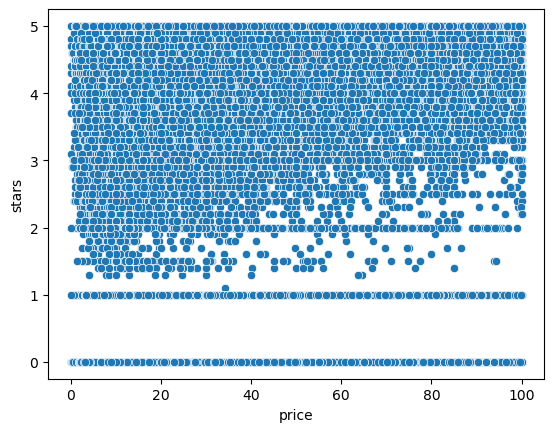

In [ ]:
sns.scatterplot(data=df_filtered, x='price', y='stars')
plt.show()
# The scatter plot does not permit real conclusions.

In [40]:
num = df_filtered.select_dtypes(include="number")
correlation_matrix = num.corr()

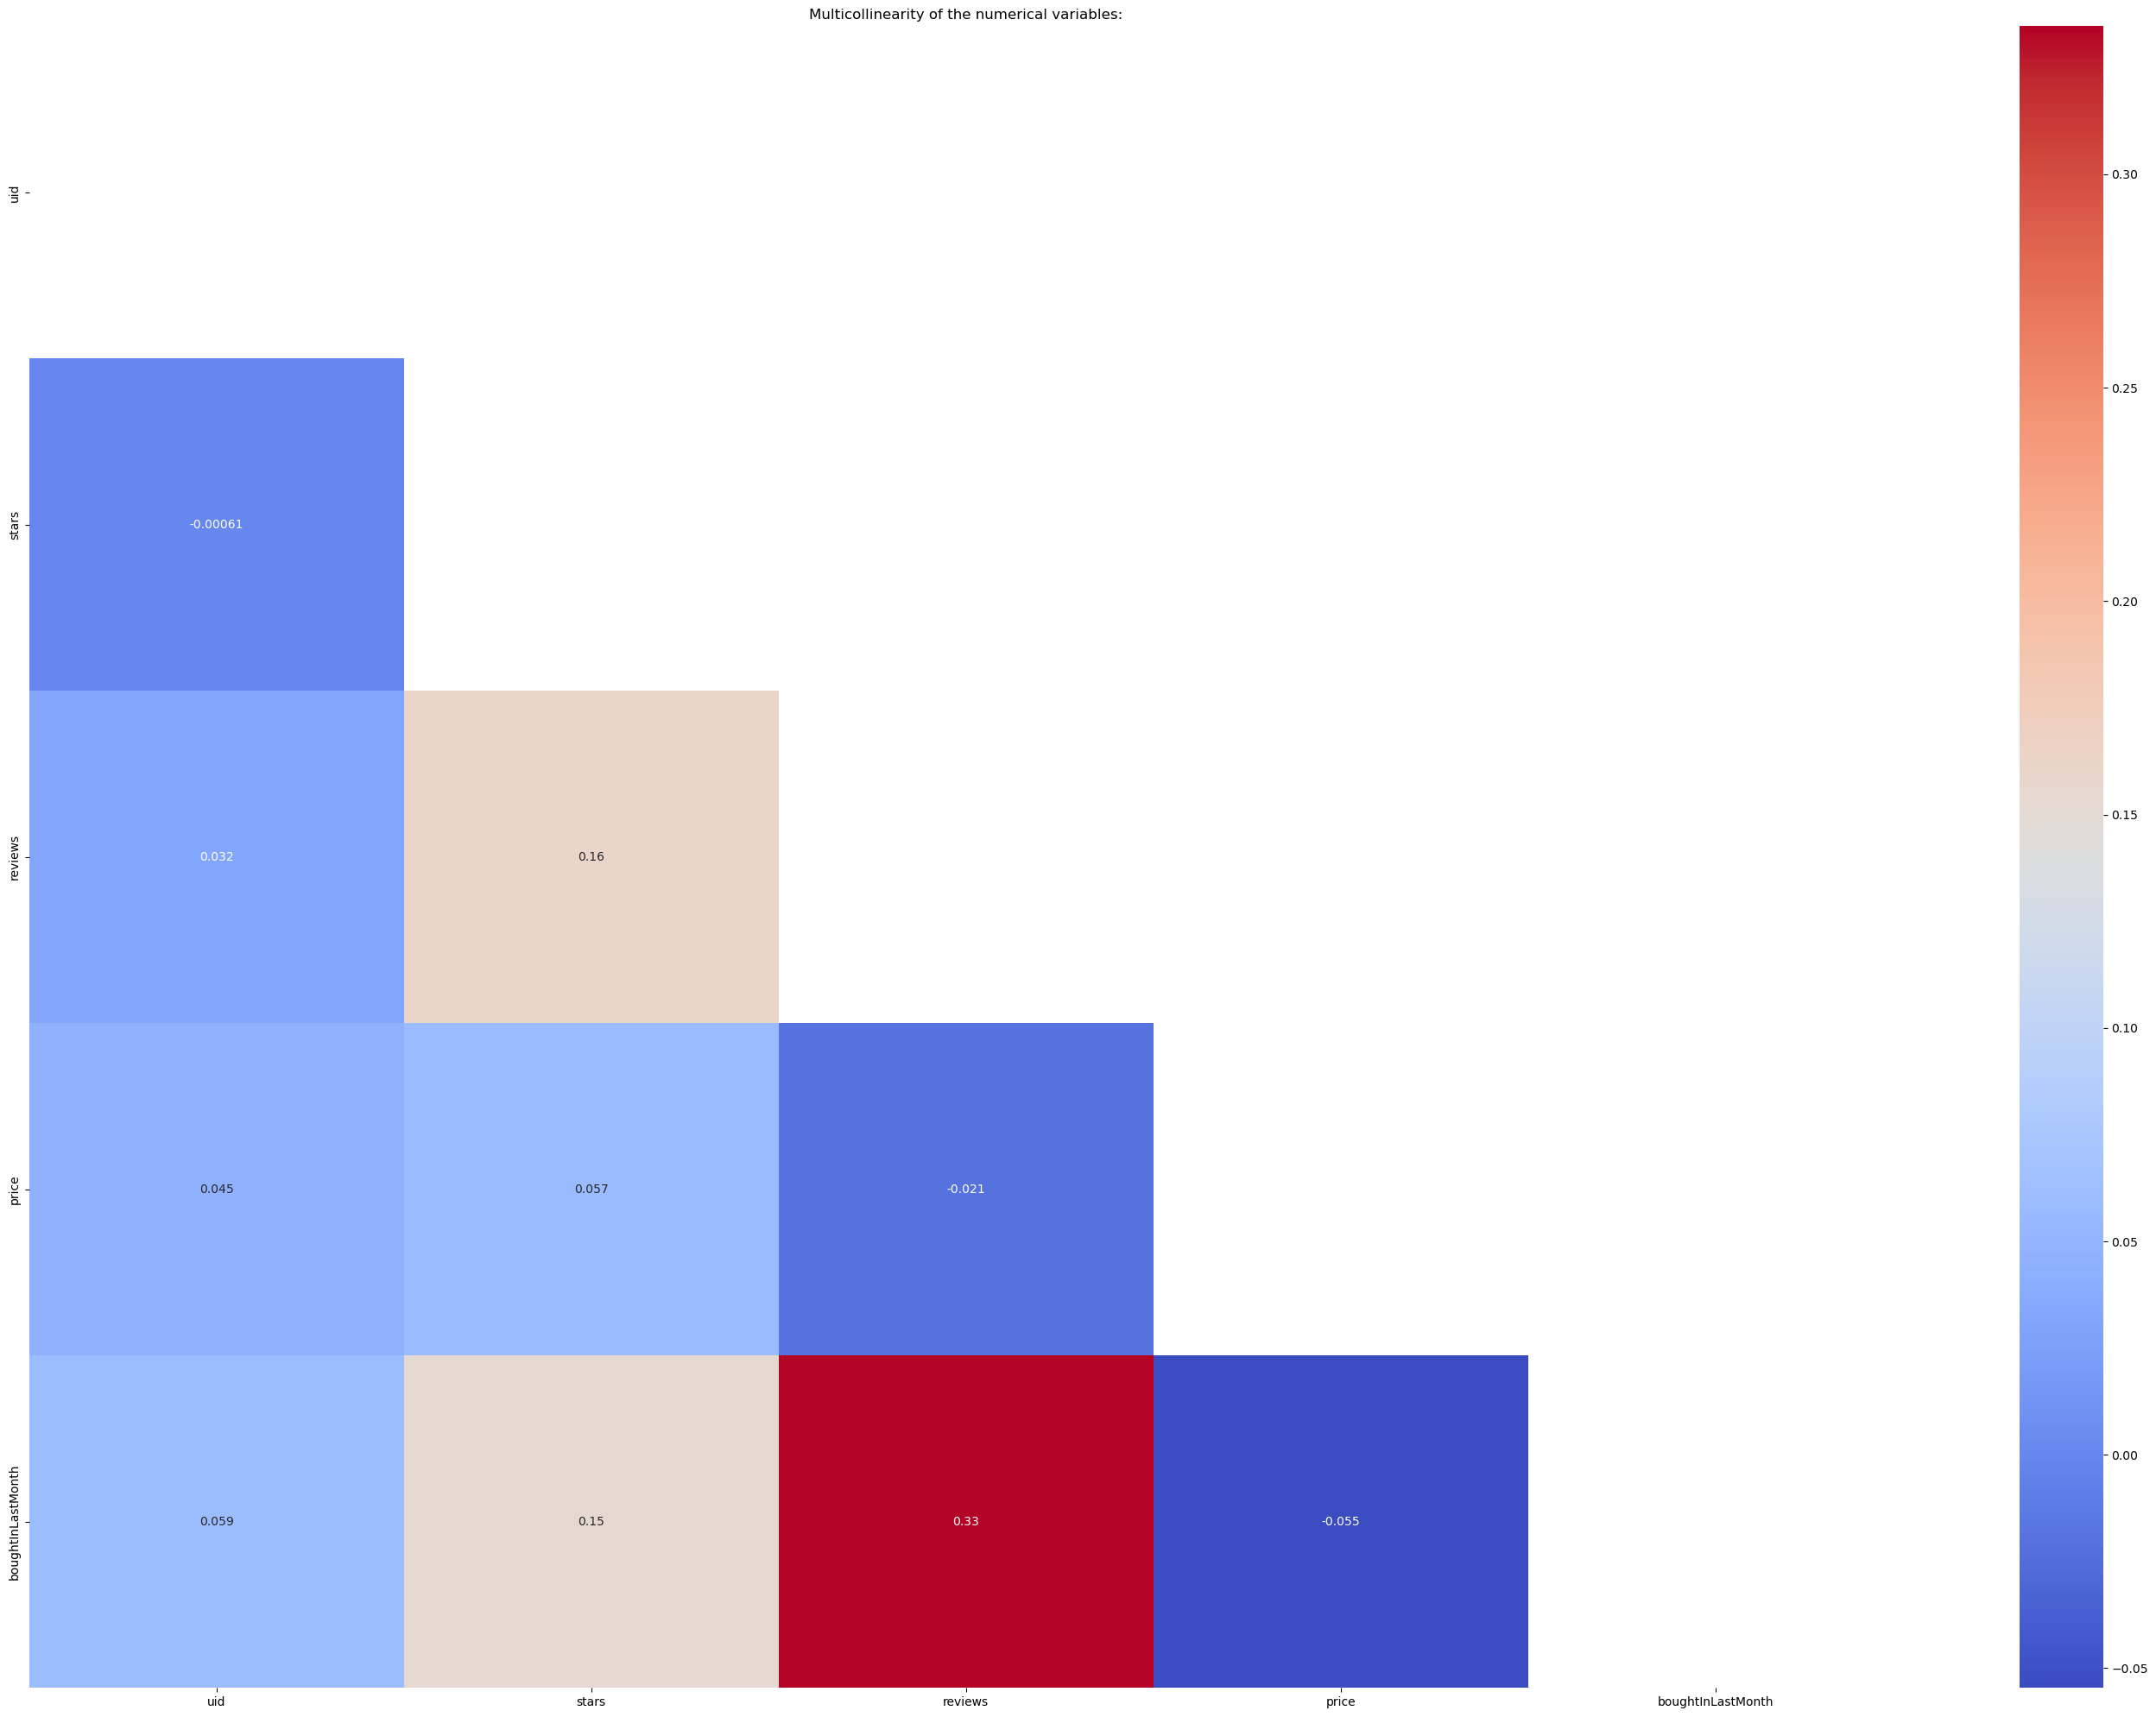

Correlation between reviews and bought-last-month is 0.33


In [51]:
import numpy as np
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Multicollinearity of the numerical variables:")
plt.show()
# There is a high correlation between "reviews" and "boughtlastmonth" -> the better the review, the more likely it is that people will buy them
print("Correlation between reviews and bought-last-month is", float(df_filtered["reviews"].corr(df_filtered["boughtInLastMonth"], method="pearson")).__round__(2))